In [1]:
import torch
print(torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

2.11.0+cu128
CUDA available: True
GPU: Tesla T4


In [5]:
!wget -q https://www2.eecs.berkeley.edu/Research/Projects/CS/vision/grouping/BSR/BSR_bsds500.tgz -O /kaggle/working/bsds.tgz
!tar -xzf /kaggle/working/bsds.tgz -C /kaggle/working/

# verify the images

In [6]:
import glob, os

root = '/kaggle/working/BSR/BSDS500/data/images'
for split in ['train', 'val', 'test']:
    files = glob.glob(f'{root}/{split}/*.jpg')
    print(split, len(files))
    

train 200
val 100
test 200


# Step 1 code: load, normalize, patch

In [7]:
import numpy as np, random
from PIL import Image
import torch
from torch.utils.data import Dataset, DataLoader

random.seed(42); np.random.seed(42); torch.manual_seed(42)

root = '/kaggle/working/BSR/BSDS500/data/images'
train_p = sorted(glob.glob(f'{root}/train/*.jpg'))
val_p   = sorted(glob.glob(f'{root}/val/*.jpg'))
test_p  = sorted(glob.glob(f'{root}/test/*.jpg'))

class PatchDataset(Dataset):
    """Random 64x64 crops from full images, normalized to [0,1]."""
    def __init__(self, paths, patch=64, per_image=30, fixed=False, seed=0):
        # Load all images into memory (small dataset, ~500 images)
        self.imgs = [np.asarray(Image.open(p).convert('RGB')) for p in paths]
        self.patch, self.per_image = patch, per_image
        self.fixed = fixed
        if fixed:  # pre-generate crop positions so val/test are reproducible
            rng = np.random.RandomState(seed)
            self.coords = []
            for img in self.imgs:
                h, w, _ = img.shape
                for _ in range(per_image):
                    self.coords.append((rng.randint(0, h - patch),
                                        rng.randint(0, w - patch)))
    def __len__(self):
        return len(self.imgs) * self.per_image
    def __getitem__(self, i):
        img = self.imgs[i // self.per_image]
        if self.fixed:
            y, x = self.coords[i]
        else:
            h, w, _ = img.shape
            y = np.random.randint(0, h - self.patch)
            x = np.random.randint(0, w - self.patch)
        crop = img[y:y+self.patch, x:x+self.patch].astype(np.float32) / 255.0
        return torch.from_numpy(crop).permute(2, 0, 1)

train_ds = PatchDataset(train_p, per_image=30)                       # random every epoch
val_ds   = PatchDataset(val_p,   per_image=10, fixed=True, seed=1)   # reproducible
test_ds  = PatchDataset(test_p,  per_image=10, fixed=True, seed=2)   # reproducible

train_dl = DataLoader(train_ds, batch_size=64, shuffle=True,  num_workers=0)
val_dl   = DataLoader(val_ds,   batch_size=64, shuffle=False, num_workers=0)
test_dl  = DataLoader(test_ds,  batch_size=64, shuffle=False, num_workers=0)

x = next(iter(train_dl))
print(x.shape, x.min().item(), x.max().item())
print("train/val/test patches:", len(train_ds), len(val_ds), len(test_ds))

torch.Size([64, 3, 64, 64]) 0.0 1.0
train/val/test patches: 6000 1000 2000


Step 2: Noise injection (Q1)

# Cell 1: Noise functions

In [8]:
import torch
import matplotlib.pyplot as plt

def add_gaussian(x, sigma):
    """Add Gaussian noise N(0, sigma^2) to images in [0,1], then clip back to [0,1]."""
    return torch.clamp(x + sigma * torch.randn_like(x), 0.0, 1.0)

def add_salt_pepper(x, amount):
    """Corrupt a fraction `amount` of pixels: half become 0 (pepper), half become 1 (salt).
    The same pixel location is corrupted in all 3 channels (like real impulse noise)."""
    b, c, h, w = x.shape
    m = torch.rand(b, 1, h, w, device=x.device)   # one random mask per pixel, shared by RGB
    x = x.clone()
    x = torch.where(m < amount / 2, torch.zeros_like(x), x)            # pepper
    x = torch.where(m > 1 - amount / 2, torch.ones_like(x), x)         # salt
    return x

def add_noise(x, kind, level):
    """Single entry point: kind is 'gaussian' or 'sp'."""
    if kind == 'gaussian':
        return add_gaussian(x, level)
    elif kind == 'sp':
        return add_salt_pepper(x, level)
    raise ValueError("kind must be 'gaussian' or 'sp'")

print(add_gaussian, add_salt_pepper, add_noise)

<function add_gaussian at 0x7e872007e700> <function add_salt_pepper at 0x7e872007e7a0> <function add_noise at 0x7e872007d9e0>


# Cell 2: Sanity check

In [9]:
clean = next(iter(train_dl))[:8]

g = add_gaussian(clean, 0.2)
s = add_salt_pepper(clean, 0.1)

print("Gaussian: range", g.min().item(), g.max().item(),
      "| MSE vs clean:", ((g - clean) ** 2).mean().item())
print("Salt&pepper: fraction of changed pixels ~",
      (s != clean).any(dim=1).float().mean().item())

Gaussian: range 0.0 1.0 | MSE vs clean: 0.03243636712431908
Salt&pepper: fraction of changed pixels ~ 0.09844970703125


# Cell 3: noise figures

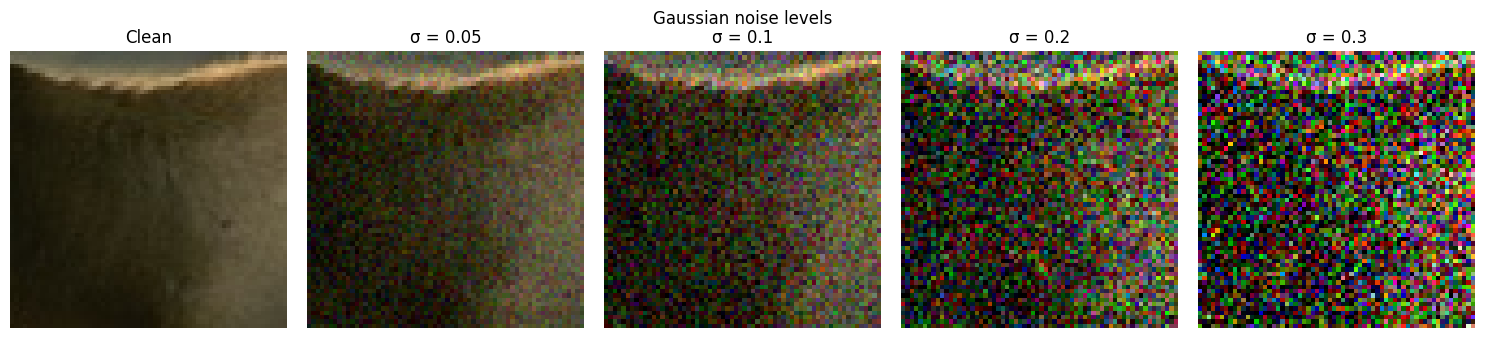

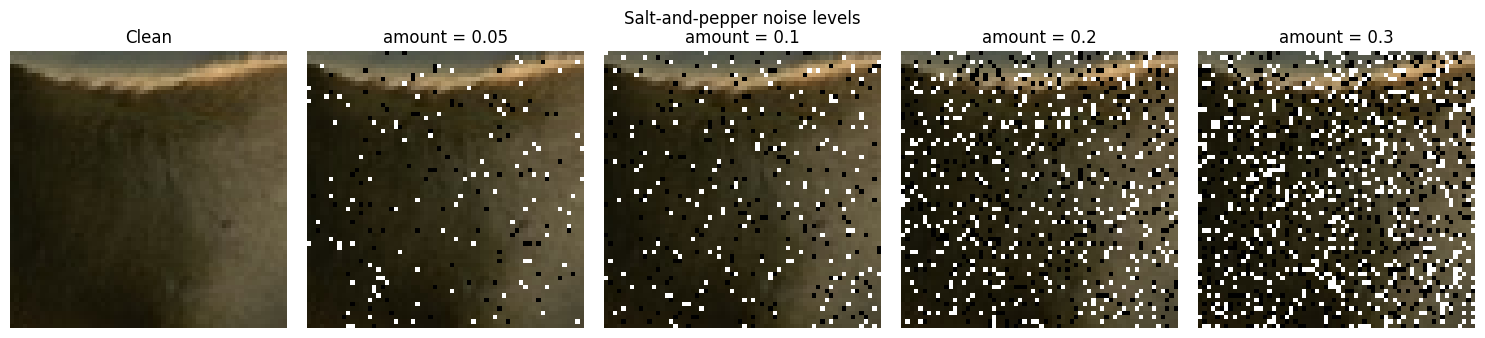

In [10]:
def show_noise_grid(clean, kind, levels, title):
    fig, axes = plt.subplots(1, len(levels) + 1, figsize=(3 * (len(levels) + 1), 3.4))
    axes[0].imshow(clean.permute(1, 2, 0).numpy()); axes[0].set_title("Clean")
    for ax, lv in zip(axes[1:], levels):
        noisy = add_noise(clean.unsqueeze(0), kind, lv)[0]
        ax.imshow(noisy.permute(1, 2, 0).numpy())
        ax.set_title(f"{'σ' if kind=='gaussian' else 'amount'} = {lv}")
    for ax in axes: ax.axis('off')
    fig.suptitle(title); plt.tight_layout()
    plt.savefig(f"/kaggle/working/noise_{kind}.png", dpi=150)
    plt.show()

sample = clean[0]
show_noise_grid(sample, 'gaussian', [0.05, 0.1, 0.2, 0.3], "Gaussian noise levels")
show_noise_grid(sample, 'sp',       [0.05, 0.1, 0.2, 0.3], "Salt-and-pepper noise levels")

# Cell 4: fixed noisy validation and test sets

In [11]:
def make_fixed_noisy(dataset, kind, level, seed):
    """Return (clean, noisy) tensors for the whole dataset with a fixed noise seed."""
    gen_state = torch.get_rng_state()
    torch.manual_seed(seed)
    cleans, noisys = [], []
    for batch in DataLoader(dataset, batch_size=256, shuffle=False, num_workers=0):
        cleans.append(batch)
        noisys.append(add_noise(batch, kind, level))
    torch.set_rng_state(gen_state)
    return torch.cat(cleans), torch.cat(noisys)

val_clean_g,  val_noisy_g  = make_fixed_noisy(val_ds,  'gaussian', 0.2, seed=10)
test_clean_g, test_noisy_g = make_fixed_noisy(test_ds, 'gaussian', 0.2, seed=20)
val_clean_s,  val_noisy_s  = make_fixed_noisy(val_ds,  'sp',       0.1, seed=11)
test_clean_s, test_noisy_s = make_fixed_noisy(test_ds, 'sp',       0.1, seed=21)

print("Gaussian  val/test:", val_noisy_g.shape, test_noisy_g.shape)
print("Salt&Pep  val/test:", val_noisy_s.shape, test_noisy_s.shape)

Gaussian  val/test: torch.Size([1000, 3, 64, 64]) torch.Size([2000, 3, 64, 64])
Salt&Pep  val/test: torch.Size([1000, 3, 64, 64]) torch.Size([2000, 3, 64, 64])


# **Cell 5: Imports, settings, model (Step 3)**

In [12]:
import math, numpy as np, pandas as pd
import torch.nn as nn
import torch.nn.functional as F

EPOCHS = 30
LR = 1e-3
DEFAULT = {'gaussian': 0.2, 'sp': 0.1}            # default noise level per noise type
NAMES = {'gaussian': 'Gaussian', 'sp': 'Salt-and-pepper'}

class DAE(nn.Module):
    """Convolutional denoising autoencoder.
    Encoder: 3x64x64 -> 32x32x32 -> 64x16x16 -> bottleneck x 8 x 8   (3 stride-2 convs, ReLU)
    Decoder: mirror image with transposed convs, Sigmoid output to stay in [0,1].
    Bottleneck size = bottleneck_channels * 8 * 8 values (input has 3*64*64 = 12288)."""
    def __init__(self, bottleneck=64):
        super().__init__()
        self.enc = nn.Sequential(
            nn.Conv2d(3, 32, 3, 2, 1), nn.ReLU(inplace=True),
            nn.Conv2d(32, 64, 3, 2, 1), nn.ReLU(inplace=True),
            nn.Conv2d(64, bottleneck, 3, 2, 1), nn.ReLU(inplace=True))
        self.dec = nn.Sequential(
            nn.ConvTranspose2d(bottleneck, 64, 4, 2, 1), nn.ReLU(inplace=True),
            nn.ConvTranspose2d(64, 32, 4, 2, 1), nn.ReLU(inplace=True),
            nn.ConvTranspose2d(32, 3, 4, 2, 1), nn.Sigmoid())
    def forward(self, x):
        return self.dec(self.enc(x))

m = DAE(64).to(device)
print(m)
print("Parameters:", sum(p.numel() for p in m.parameters()))
print("Latent shape:", m.enc(torch.zeros(1, 3, 64, 64, device=device)).shape)
del m

DAE(
  (enc): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(32, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (3): ReLU(inplace=True)
    (4): Conv2d(64, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (5): ReLU(inplace=True)
  )
  (dec): Sequential(
    (0): ConvTranspose2d(64, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): ConvTranspose2d(64, 32, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (3): ReLU(inplace=True)
    (4): ConvTranspose2d(32, 3, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (5): Sigmoid()
  )
)
Parameters: 156259
Latent shape: torch.Size([1, 64, 8, 8])


# **cell 6: Matrix**

In [13]:
def _gauss_window(size=11, sigma=1.5, ch=3):
    c = torch.arange(size).float() - size // 2
    g = torch.exp(-(c ** 2) / (2 * sigma ** 2)); g /= g.sum()
    w = g[:, None] * g[None, :]
    return w.expand(ch, 1, size, size).contiguous()

WIN = _gauss_window().to(device)

def ssim_torch(x, y):
    """Per-image SSIM for batches in [0,1], shape Bx3xHxW (valid-region Gaussian window)."""
    C1, C2 = 0.01 ** 2, 0.03 ** 2
    mu_x = F.conv2d(x, WIN, groups=3); mu_y = F.conv2d(y, WIN, groups=3)
    sxx = F.conv2d(x * x, WIN, groups=3) - mu_x ** 2
    syy = F.conv2d(y * y, WIN, groups=3) - mu_y ** 2
    sxy = F.conv2d(x * y, WIN, groups=3) - mu_x * mu_y
    s = ((2 * mu_x * mu_y + C1) * (2 * sxy + C2)) / ((mu_x ** 2 + mu_y ** 2 + C1) * (sxx + syy + C2))
    return s.mean(dim=(1, 2, 3))

@torch.no_grad()
def compute_metrics(clean, pred):
    """Mean MSE, PSNR (dB) and SSIM over a set of images (CPU or GPU tensors)."""
    mses, psnrs, ssims = [], [], []
    for i in range(0, len(clean), 500):
        c, p = clean[i:i+500].to(device), pred[i:i+500].to(device)
        mse = ((c - p) ** 2).mean(dim=(1, 2, 3))
        mses.append(mse)
        psnrs.append(10 * torch.log10(1.0 / mse.clamp_min(1e-10)))
        ssims.append(ssim_torch(c, p))
    return {'MSE': torch.cat(mses).mean().item(),
            'PSNR': torch.cat(psnrs).mean().item(),
            'SSIM': torch.cat(ssims).mean().item()}

# Fixed noisy val/test sets for any (noise type, level), cached
FIXED = {}
SEEDS = {('gaussian', 'val'): 10, ('gaussian', 'test'): 20, ('sp', 'val'): 11, ('sp', 'test'): 21}
def get_fixed(kind, level, split):
    key = (kind, level, split)
    if key not in FIXED:
        ds = val_ds if split == 'val' else test_ds
        FIXED[key] = make_fixed_noisy(ds, kind, level, SEEDS[(kind, split)])
    return FIXED[key]

@torch.no_grad()
def denoise(model, noisy):
    model.eval()
    return torch.cat([model(noisy[i:i+500].to(device)).cpu() for i in range(0, len(noisy), 500)])

def evaluate(model, kind, level):
    """Returns (metrics of denoised output, metrics of the noisy input as baseline) on the test set."""
    clean, noisy = get_fixed(kind, level, 'test')
    return compute_metrics(clean, denoise(model, noisy)), compute_metrics(clean, noisy)

# Cross-check my SSIM against scikit-image on 20 images
from skimage.metrics import structural_similarity as ssim_sk
c, n = test_clean_g[:20], test_noisy_g[:20]
mine = ssim_torch(c.to(device), n.to(device)).mean().item()
ref = np.mean([ssim_sk(c[i].permute(1, 2, 0).numpy(), n[i].permute(1, 2, 0).numpy(), channel_axis=2,
                       data_range=1.0, gaussian_weights=True, sigma=1.5, use_sample_covariance=False)
               for i in range(20)])
print(f"SSIM mine={mine:.4f} | skimage={ref:.4f}")

SSIM mine=0.1861 | skimage=0.1861


# Cell 7: Training function (prints nothing)

In [15]:
import time
MODELS, HIST = {}, {}

def train_dae(kind, level, bottleneck, epochs=EPOCHS, lr=LR):
    """Train a DAE: input = clean + fresh noise each batch, target = clean, loss = MSE."""
    torch.manual_seed(0)
    model = DAE(bottleneck).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    crit = nn.MSELoss()
    vclean, vnoisy = [t.to(device) for t in get_fixed(kind, level, 'val')]
    best, best_state, hist, t0 = float('inf'), None, {'train': [], 'val': []}, time.time()
    for ep in range(1, epochs + 1):
        model.train(); tot = n = 0
        for x in train_dl:
            x = x.to(device)
            loss = crit(model(add_noise(x, kind, level)), x)
            opt.zero_grad(); loss.backward(); opt.step()
            tot += loss.item() * x.size(0); n += x.size(0)
        model.eval()
        with torch.no_grad():
            vloss = crit(model(vnoisy), vclean).item()
        hist['train'].append(tot / n); hist['val'].append(vloss)
        if vloss < best:
            best = vloss; best_state = {k: v.clone() for k, v in model.state_dict().items()}
        if ep % 5 == 0 or ep == 1:
            print(f"[{kind} {level} b={bottleneck}] ep {ep:2d}/{epochs} "
                  f"train {hist['train'][-1]:.5f} val {vloss:.5f} ({time.time()-t0:.0f}s)")
    model.load_state_dict(best_state)
    return model, hist

def get_model(kind, level, bottleneck):
    key = (kind, level, bottleneck)
    if key not in MODELS:
        MODELS[key], HIST[key] = train_dae(kind, level, bottleneck)
        torch.save(MODELS[key].state_dict(), f'/kaggle/working/dae_{kind}_{level}_b{bottleneck}.pth')
    return MODELS[key]

# Cell 8: Train the two main models

In [16]:
model_g = get_model('gaussian', DEFAULT['gaussian'], 64)   # sigma = 0.2
model_s = get_model('sp',       DEFAULT['sp'],       64)   # 10% salt-and-pepper

[gaussian 0.2 b=64] ep  1/30 train 0.02642 val 0.01217 (1s)
[gaussian 0.2 b=64] ep  5/30 train 0.00722 val 0.00709 (5s)
[gaussian 0.2 b=64] ep 10/30 train 0.00618 val 0.00595 (9s)
[gaussian 0.2 b=64] ep 15/30 train 0.00482 val 0.00500 (13s)
[gaussian 0.2 b=64] ep 20/30 train 0.00442 val 0.00481 (18s)
[gaussian 0.2 b=64] ep 25/30 train 0.00414 val 0.00437 (22s)
[gaussian 0.2 b=64] ep 30/30 train 0.00393 val 0.00412 (26s)
[sp 0.1 b=64] ep  1/30 train 0.02706 val 0.01186 (1s)
[sp 0.1 b=64] ep  5/30 train 0.00729 val 0.00704 (4s)
[sp 0.1 b=64] ep 10/30 train 0.00609 val 0.00576 (9s)
[sp 0.1 b=64] ep 15/30 train 0.00455 val 0.00470 (13s)
[sp 0.1 b=64] ep 20/30 train 0.00400 val 0.00435 (17s)
[sp 0.1 b=64] ep 25/30 train 0.00341 val 0.00370 (22s)
[sp 0.1 b=64] ep 30/30 train 0.00328 val 0.00345 (26s)


# Cell 9: Loss curves and main test results

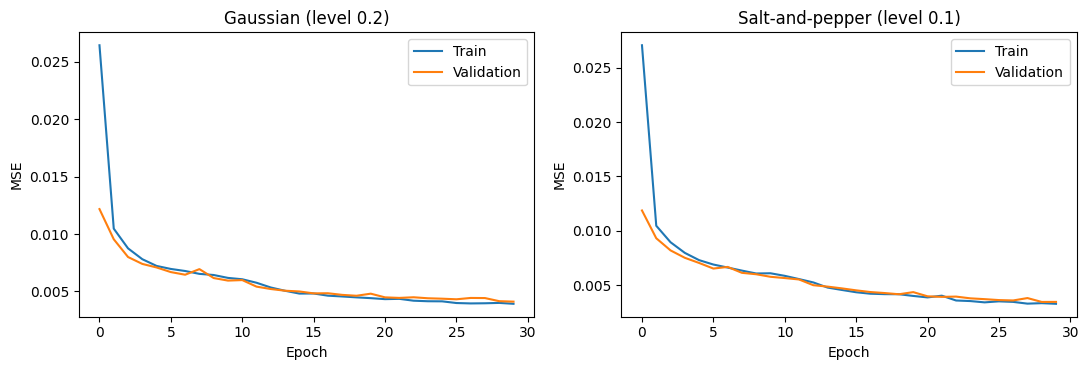

,Noise,Level,Input,MSE,PSNR,SSIM
0,Gaussian,0.2,Noisy (baseline),0.0329,14.8606,0.2019
1,Gaussian,0.2,DAE output,0.0042,25.1560,0.6578
2,Salt-and-pepper,0.1,Noisy (baseline),0.0318,15.0182,0.2628
3,Salt-and-pepper,0.1,DAE output,0.0035,26.8068,0.7385


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, kind in zip(axes, ['gaussian', 'sp']):
    h = HIST[(kind, DEFAULT[kind], 64)]
    ax.plot(h['train'], label='Train'); ax.plot(h['val'], label='Validation')
    ax.set_title(f"{NAMES[kind]} (level {DEFAULT[kind]})"); ax.set_xlabel('Epoch'); ax.set_ylabel('MSE'); ax.legend()
plt.tight_layout(); plt.savefig('/kaggle/working/loss_curves.png', dpi=150); plt.show()

rows = []
for kind, model in [('gaussian', model_g), ('sp', model_s)]:
    res, base = evaluate(model, kind, DEFAULT[kind])
    rows.append({'Noise': NAMES[kind], 'Level': DEFAULT[kind], 'Input': 'Noisy (baseline)', **base})
    rows.append({'Noise': NAMES[kind], 'Level': DEFAULT[kind], 'Input': 'DAE output', **res})
main_df = pd.DataFrame(rows)
main_df.to_csv('/kaggle/working/main_results.csv', index=False)
display(main_df.round(4))

# Cell 10: Clean / Noisy / Denoised figures
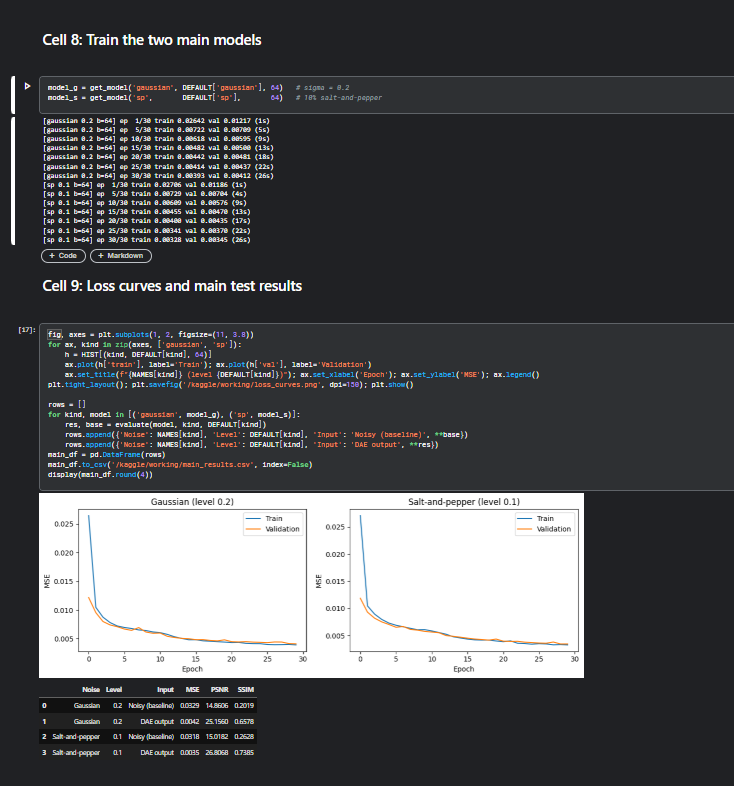

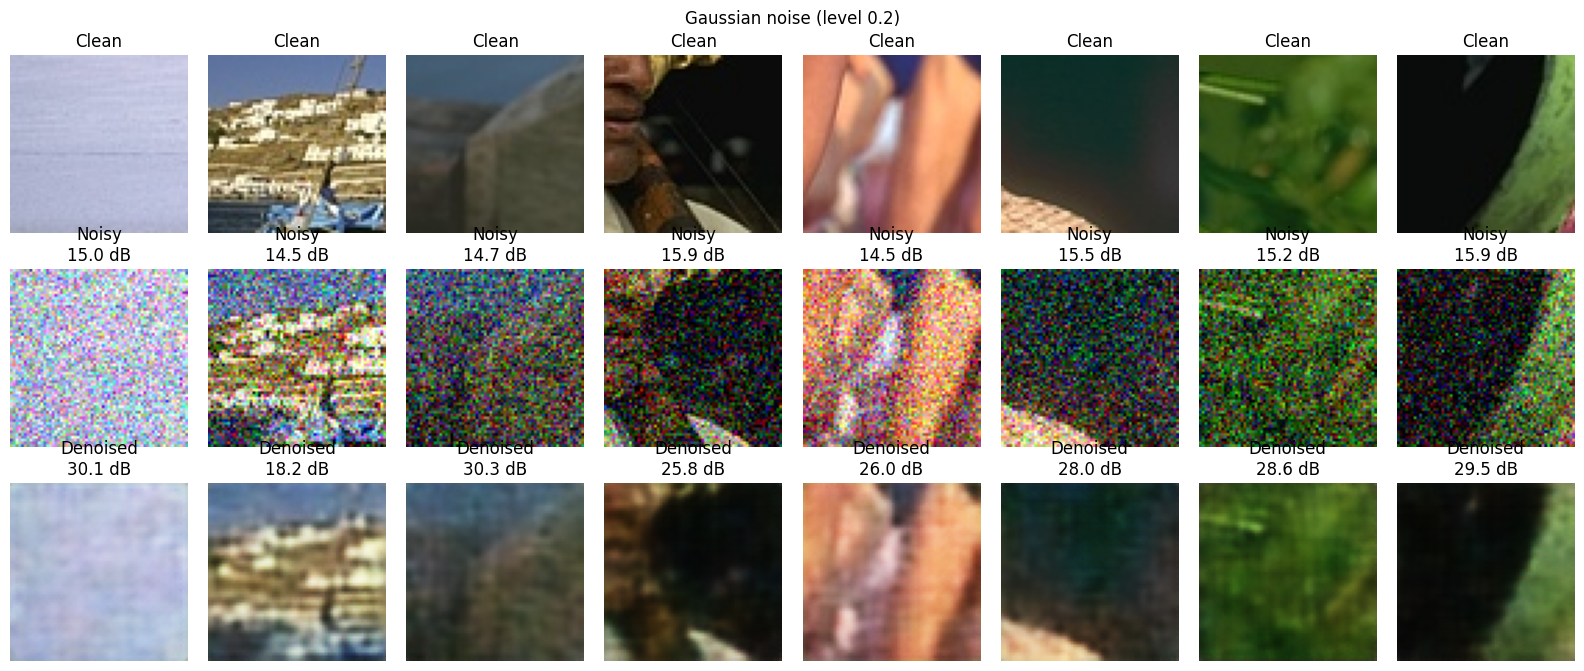

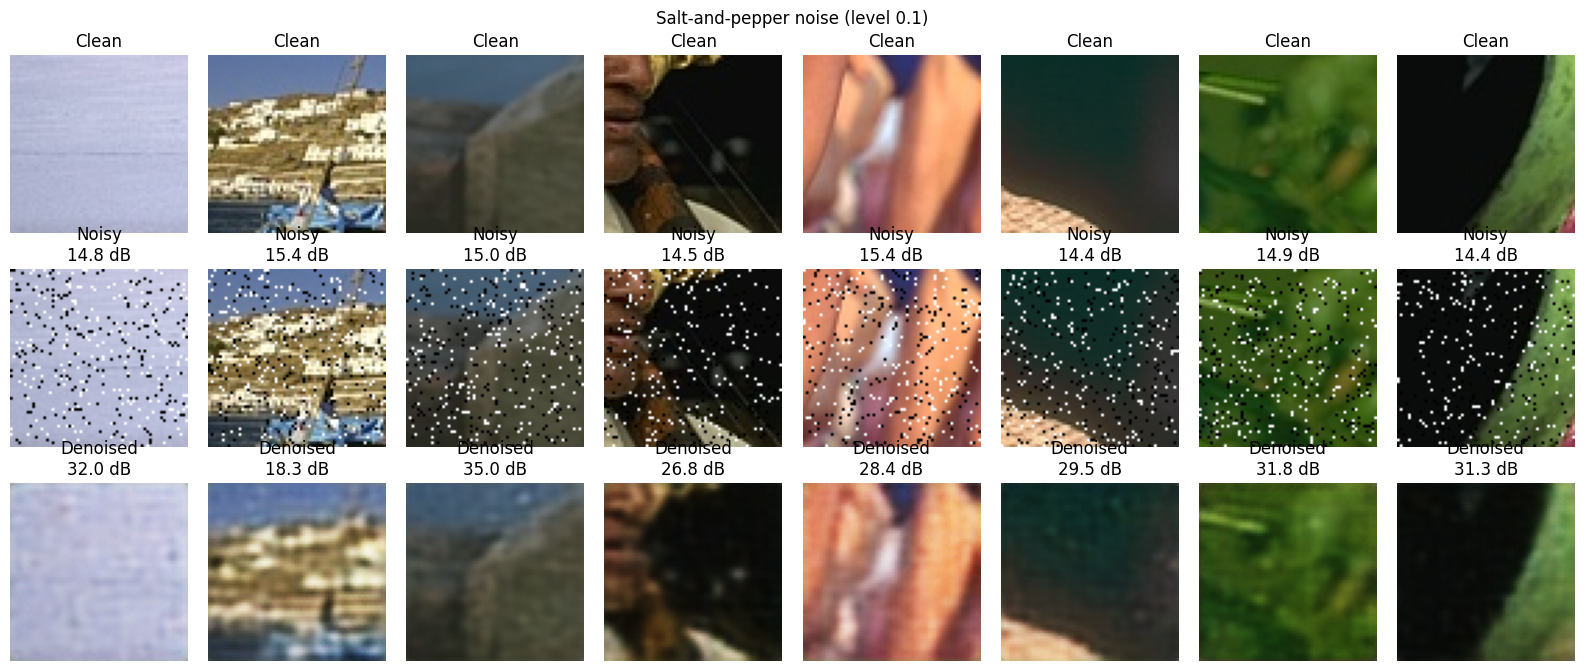

In [18]:
def psnr_img(a, b):
    return 10 * math.log10(1.0 / max(((a - b) ** 2).mean().item(), 1e-10))

def show_results(model, kind, level, n=8):
    clean, noisy = get_fixed(kind, level, 'test')
    idx = list(range(0, len(clean), len(clean) // n))[:n]          # patches from different images
    model.eval()
    with torch.no_grad():
        den = model(noisy[idx].to(device)).cpu()
    fig, axes = plt.subplots(3, n, figsize=(2 * n, 6.8))
    for j, i in enumerate(idx):
        axes[0, j].imshow(clean[i].permute(1, 2, 0)); axes[0, j].set_title('Clean')
        axes[1, j].imshow(noisy[i].permute(1, 2, 0)); axes[1, j].set_title(f'Noisy\n{psnr_img(clean[i], noisy[i]):.1f} dB')
        axes[2, j].imshow(den[j].permute(1, 2, 0));   axes[2, j].set_title(f'Denoised\n{psnr_img(clean[i], den[j]):.1f} dB')
    for ax in axes.ravel(): ax.axis('off')
    fig.suptitle(f"{NAMES[kind]} noise (level {level})"); plt.tight_layout()
    plt.savefig(f'/kaggle/working/results_{kind}.png', dpi=150); plt.show()

show_results(model_g, 'gaussian', DEFAULT['gaussian'])
show_results(model_s, 'sp',       DEFAULT['sp'])

# Cell 11: Experiment A, noise levels

In [19]:
LEVELS = [0.05, 0.1, 0.2, 0.3]

# A1: a separate model per noise level, tested at the same level
rowsA = []
for kind in ['gaussian', 'sp']:
    for lv in LEVELS:
        res, base = evaluate(get_model(kind, lv, 64), kind, lv)
        rowsA.append({'Noise': NAMES[kind], 'Level': lv,
                      'Noisy_MSE': base['MSE'], 'Noisy_PSNR': base['PSNR'], 'Noisy_SSIM': base['SSIM'],
                      'DAE_MSE': res['MSE'], 'DAE_PSNR': res['PSNR'], 'DAE_SSIM': res['SSIM']})
dfA = pd.DataFrame(rowsA); dfA.to_csv('/kaggle/working/exp_noise_levels.csv', index=False)
display(dfA.round(4))

# A2: model trained at the default level, tested at every level
rowsC = []
for kind in ['gaussian', 'sp']:
    mdl = get_model(kind, DEFAULT[kind], 64)
    for lv in LEVELS:
        res, _ = evaluate(mdl, kind, lv)
        rowsC.append({'Noise': NAMES[kind], 'Trained_at': DEFAULT[kind], 'Test_level': lv, **res})
dfC = pd.DataFrame(rowsC); dfC.to_csv('/kaggle/working/exp_cross_level.csv', index=False)
display(dfC.round(4))

[gaussian 0.05 b=64] ep  1/30 train 0.02554 val 0.01176 (1s)
[gaussian 0.05 b=64] ep  5/30 train 0.00640 val 0.00606 (4s)
[gaussian 0.05 b=64] ep 10/30 train 0.00454 val 0.00445 (9s)
[gaussian 0.05 b=64] ep 15/30 train 0.00352 val 0.00368 (13s)
[gaussian 0.05 b=64] ep 20/30 train 0.00314 val 0.00332 (18s)
[gaussian 0.05 b=64] ep 25/30 train 0.00278 val 0.00301 (22s)
[gaussian 0.05 b=64] ep 30/30 train 0.00256 val 0.00275 (27s)
[gaussian 0.1 b=64] ep  1/30 train 0.02703 val 0.01125 (1s)
[gaussian 0.1 b=64] ep  5/30 train 0.00643 val 0.00607 (4s)
[gaussian 0.1 b=64] ep 10/30 train 0.00469 val 0.00465 (9s)
[gaussian 0.1 b=64] ep 15/30 train 0.00393 val 0.00400 (14s)
[gaussian 0.1 b=64] ep 20/30 train 0.00341 val 0.00359 (18s)
[gaussian 0.1 b=64] ep 25/30 train 0.00318 val 0.00329 (23s)
[gaussian 0.1 b=64] ep 30/30 train 0.00293 val 0.00307 (27s)
[gaussian 0.3 b=64] ep  1/30 train 0.02808 val 0.01261 (1s)
[gaussian 0.3 b=64] ep  5/30 train 0.00764 val 0.00740 (4s)
[gaussian 0.3 b=64] ep 10

,Noise,Level,Noisy_MSE,Noisy_PSNR,Noisy_SSIM,DAE_MSE,DAE_PSNR,DAE_SSIM
0,Gaussian,0.05,0.0024,26.2090,0.6364,0.0028,27.7539,0.7813
1,Gaussian,0.10,0.0092,20.3716,0.3960,0.0031,26.8328,0.7357
2,Gaussian,0.20,0.0329,14.8606,0.2019,0.0042,25.1560,0.6578
3,Gaussian,0.30,0.0635,11.9921,0.1251,0.0050,24.3083,0.6193
4,Salt-and-pepper,0.05,0.0159,18.0273,0.4336,0.0031,27.5593,0.7701
5,Salt-and-pepper,0.10,0.0318,15.0182,0.2628,0.0035,26.8068,0.7385
6,Salt-and-pepper,0.20,0.0636,12.0005,0.1425,0.0041,25.9989,0.6937
7,Salt-and-pepper,0.30,0.0954,10.2408,0.0931,0.0047,25.2491,0.6521


,Noise,Trained_at,Test_level,MSE,PSNR,SSIM
0,Gaussian,0.2,0.05,0.0039,25.7585,0.6988
1,Gaussian,0.2,0.10,0.0039,25.6688,0.6954
2,Gaussian,0.2,0.20,0.0042,25.1560,0.6578
3,Gaussian,0.2,0.30,0.0060,22.9339,0.5529
4,Salt-and-pepper,0.1,0.05,0.0034,27.1261,0.7570
5,Salt-and-pepper,0.1,0.10,0.0035,26.8068,0.7385
6,Salt-and-pepper,0.1,0.20,0.0042,25.3439,0.6740
7,Salt-and-pepper,0.1,0.30,0.0057,23.3462,0.5764


# Cell 12: Figures for Experiment A

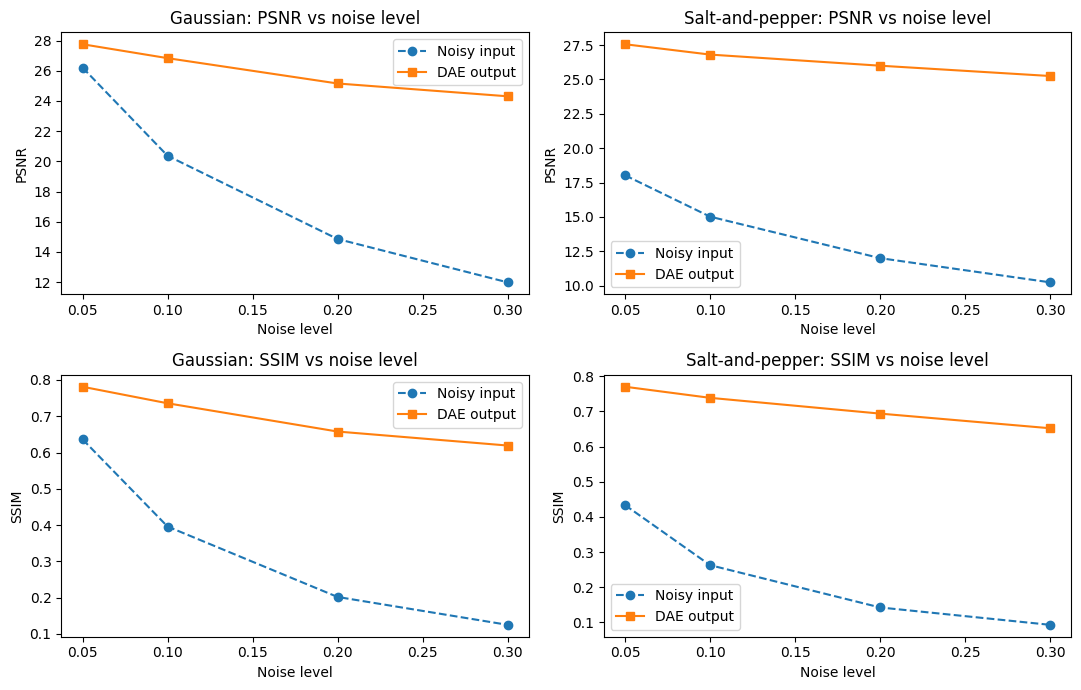

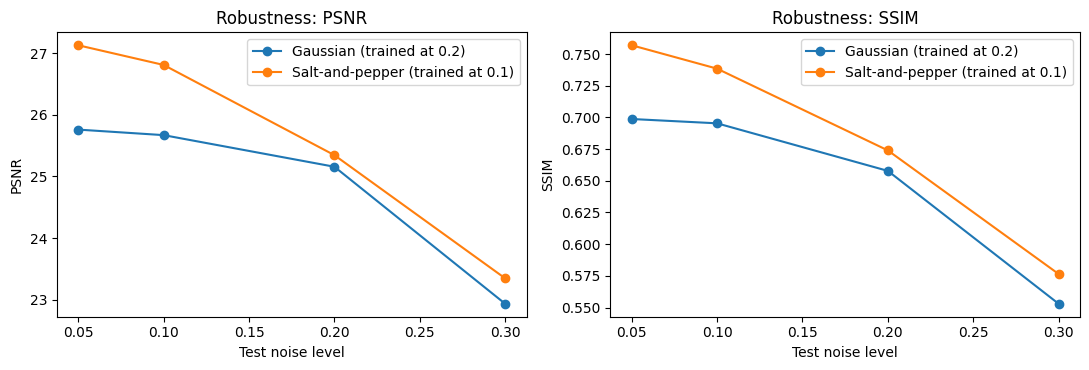

In [20]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for col, kind in enumerate(['gaussian', 'sp']):
    d = dfA[dfA.Noise == NAMES[kind]]
    for row, met in enumerate(['PSNR', 'SSIM']):
        ax = axes[row, col]
        ax.plot(d.Level, d[f'Noisy_{met}'], 'o--', label='Noisy input')
        ax.plot(d.Level, d[f'DAE_{met}'], 's-', label='DAE output')
        ax.set_title(f"{NAMES[kind]}: {met} vs noise level"); ax.set_xlabel('Noise level'); ax.set_ylabel(met); ax.legend()
plt.tight_layout(); plt.savefig('/kaggle/working/fig_noise_levels.png', dpi=150); plt.show()

# Robustness: train at default level, test at all levels
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, met in zip(axes, ['PSNR', 'SSIM']):
    for kind in ['gaussian', 'sp']:
        d = dfC[dfC.Noise == NAMES[kind]]
        ax.plot(d.Test_level, d[met], 'o-', label=f"{NAMES[kind]} (trained at {DEFAULT[kind]})")
    ax.set_xlabel('Test noise level'); ax.set_ylabel(met); ax.set_title(f'Robustness: {met}'); ax.legend()
plt.tight_layout(); plt.savefig('/kaggle/working/fig_robustness.png', dpi=150); plt.show()

# Cell 13: Experiment B, bottleneck sizes

In [21]:
BOTTLENECKS = [8, 16, 64, 128]
rowsB = []
for kind in ['gaussian', 'sp']:
    for b in BOTTLENECKS:
        mdl = get_model(kind, DEFAULT[kind], b)
        res, base = evaluate(mdl, kind, DEFAULT[kind])
        rowsB.append({'Noise': NAMES[kind], 'Level': DEFAULT[kind], 'Bottleneck_ch': b,
                      'Latent_size': b * 64, 'Compression': round(12288 / (b * 64), 1),
                      'Params': sum(p.numel() for p in mdl.parameters()), **res})
dfB = pd.DataFrame(rowsB); dfB.to_csv('/kaggle/working/exp_bottleneck.csv', index=False)
display(dfB.round(4))

[gaussian 0.2 b=8] ep  1/30 train 0.03218 val 0.01621 (1s)
[gaussian 0.2 b=8] ep  5/30 train 0.00850 val 0.00812 (4s)
[gaussian 0.2 b=8] ep 10/30 train 0.00713 val 0.00703 (8s)
[gaussian 0.2 b=8] ep 15/30 train 0.00649 val 0.00633 (12s)
[gaussian 0.2 b=8] ep 20/30 train 0.00616 val 0.00628 (16s)
[gaussian 0.2 b=8] ep 25/30 train 0.00530 val 0.00542 (21s)
[gaussian 0.2 b=8] ep 30/30 train 0.00500 val 0.00531 (25s)
[gaussian 0.2 b=16] ep  1/30 train 0.02978 val 0.01517 (1s)
[gaussian 0.2 b=16] ep  5/30 train 0.00784 val 0.00752 (4s)
[gaussian 0.2 b=16] ep 10/30 train 0.00659 val 0.00637 (8s)
[gaussian 0.2 b=16] ep 15/30 train 0.00565 val 0.00573 (13s)
[gaussian 0.2 b=16] ep 20/30 train 0.00487 val 0.00525 (17s)
[gaussian 0.2 b=16] ep 25/30 train 0.00459 val 0.00483 (21s)
[gaussian 0.2 b=16] ep 30/30 train 0.00444 val 0.00460 (25s)
[gaussian 0.2 b=128] ep  1/30 train 0.02698 val 0.01222 (1s)
[gaussian 0.2 b=128] ep  5/30 train 0.00654 val 0.00621 (5s)
[gaussian 0.2 b=128] ep 10/30 train 0

,Noise,Level,Bottleneck_ch,Latent_size,Compression,Params,MSE,PSNR,SSIM
0,Gaussian,0.2,8,512,24.0,66603,0.0054,24.2798,0.6088
1,Gaussian,0.2,16,1024,12.0,79411,0.0047,24.8767,0.6356
2,Gaussian,0.2,64,4096,3.0,156259,0.0042,25.1560,0.6578
3,Gaussian,0.2,128,8192,1.5,258723,0.0037,25.6401,0.6863
4,Salt-and-pepper,0.1,8,512,24.0,66603,0.0051,25.3281,0.6457
5,Salt-and-pepper,0.1,16,1024,12.0,79411,0.0042,26.0184,0.6931
6,Salt-and-pepper,0.1,64,4096,3.0,156259,0.0035,26.8068,0.7385
7,Salt-and-pepper,0.1,128,8192,1.5,258723,0.0033,26.9648,0.7465


# Cell 14: Figures for Experiment B

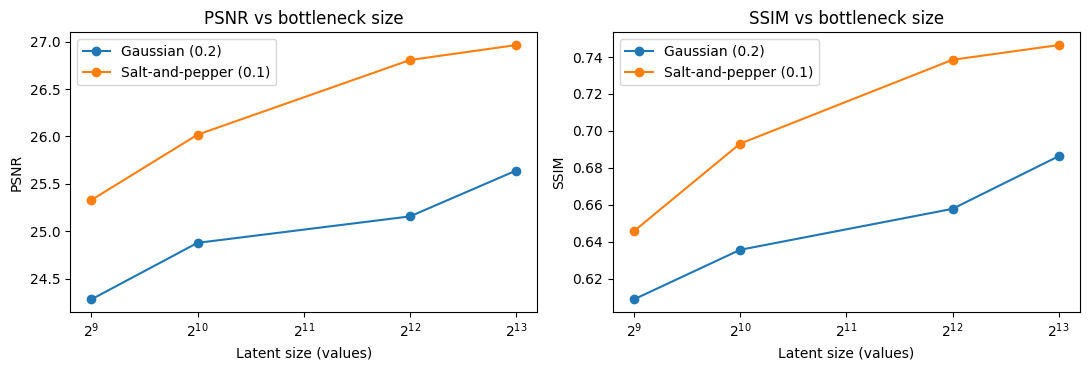

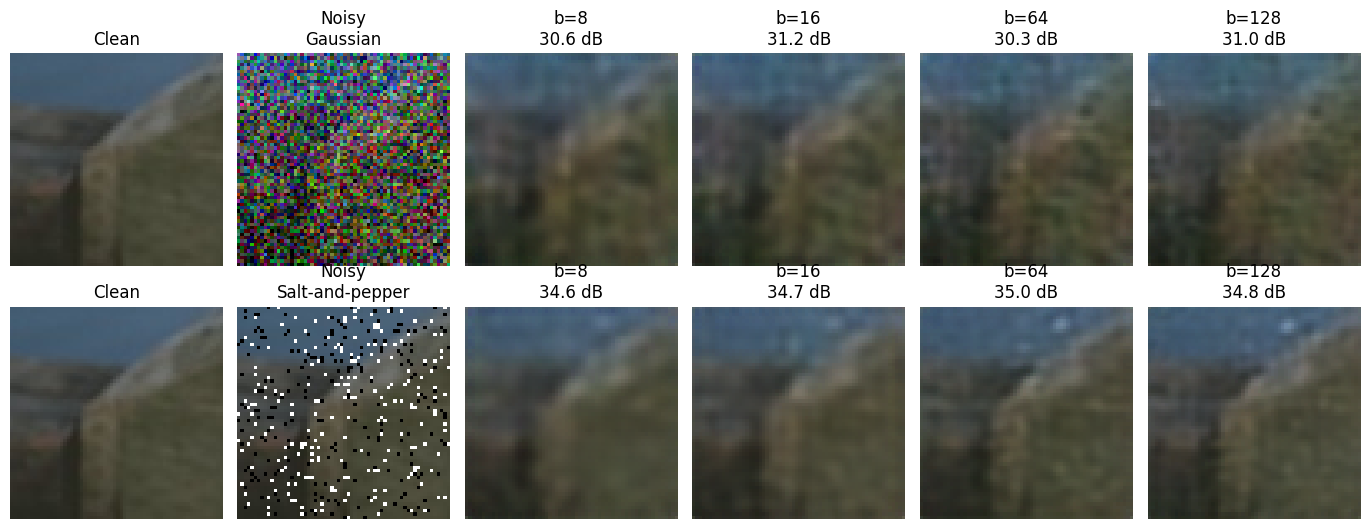

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, met in zip(axes, ['PSNR', 'SSIM']):
    for kind in ['gaussian', 'sp']:
        d = dfB[dfB.Noise == NAMES[kind]]
        ax.plot(d.Latent_size, d[met], 'o-', label=f"{NAMES[kind]} ({DEFAULT[kind]})")
    ax.set_xscale('log', base=2); ax.set_xlabel('Latent size (values)'); ax.set_ylabel(met)
    ax.set_title(f'{met} vs bottleneck size'); ax.legend()
plt.tight_layout(); plt.savefig('/kaggle/working/fig_bottleneck.png', dpi=150); plt.show()

# Visual comparison: same test patch, each bottleneck size
idx = 500
fig, axes = plt.subplots(2, 2 + len(BOTTLENECKS), figsize=(2.3 * (2 + len(BOTTLENECKS)), 5.4))
for r, kind in enumerate(['gaussian', 'sp']):
    clean, noisy = get_fixed(kind, DEFAULT[kind], 'test')
    axes[r, 0].imshow(clean[idx].permute(1, 2, 0)); axes[r, 0].set_title('Clean')
    axes[r, 1].imshow(noisy[idx].permute(1, 2, 0)); axes[r, 1].set_title(f'Noisy\n{NAMES[kind]}')
    for k, b in enumerate(BOTTLENECKS):
        mdl = get_model(kind, DEFAULT[kind], b); mdl.eval()
        with torch.no_grad():
            out = mdl(noisy[idx:idx+1].to(device)).cpu()[0]
        axes[r, 2 + k].imshow(out.permute(1, 2, 0))
        axes[r, 2 + k].set_title(f'b={b}\n{psnr_img(clean[idx], out):.1f} dB')
for ax in axes.ravel(): ax.axis('off')
plt.tight_layout(); plt.savefig('/kaggle/working/fig_bottleneck_visual.png', dpi=150); plt.show()

# Cell 15: Report-ready summary tables

In [23]:
# Table 1: PSNR of DAE output, rows = noise level, columns = noise type
t1 = dfA.pivot(index='Level', columns='Noise', values='DAE_PSNR').round(2)
# Table 2: PSNR gain over noisy input (dB)
dfA['PSNR_gain'] = dfA.DAE_PSNR - dfA.Noisy_PSNR
t2 = dfA.pivot(index='Level', columns='Noise', values='PSNR_gain').round(2)
# Table 3: PSNR and SSIM by bottleneck
t3 = dfB.pivot(index='Bottleneck_ch', columns='Noise', values=['PSNR', 'SSIM']).round(4)

print("Table 1: DAE PSNR (dB) by noise level"); display(t1)
print("Table 2: PSNR gain over noisy input (dB)"); display(t2)
print("Table 3: Bottleneck size vs PSNR/SSIM"); display(t3)

Table 1: DAE PSNR (dB) by noise level


Noise,Gaussian,Salt-and-pepper
Level,,
0.05,27.75,27.56
0.10,26.83,26.81
0.20,25.16,26.00
0.30,24.31,25.25


Table 2: PSNR gain over noisy input (dB)


Noise,Gaussian,Salt-and-pepper
Level,,
0.05,1.54,9.53
0.10,6.46,11.79
0.20,10.30,14.00
0.30,12.32,15.01


Table 3: Bottleneck size vs PSNR/SSIM


PSNR                     SSIM                
Noise         Gaussian Salt-and-pepper Gaussian Salt-and-pepper
Bottleneck_ch                                                  
8              24.2798         25.3281   0.6088          0.6457
16             24.8767         26.0184   0.6356          0.6931
64             25.1560         26.8068   0.6578          0.7385
128            25.6401         26.9648   0.6863          0.7465

# Cell 16: Final file list

In [24]:
import os
for f in sorted(os.listdir('/kaggle/working')):
    if f.endswith(('.png', '.csv', '.pth')):
        print(f, f"{os.path.getsize('/kaggle/working/'+f)/1e3:.0f} KB")

dae_gaussian_0.05_b64.pth 630 KB
dae_gaussian_0.1_b64.pth 630 KB
dae_gaussian_0.2_b128.pth 1040 KB
dae_gaussian_0.2_b16.pth 323 KB
dae_gaussian_0.2_b64.pth 630 KB
dae_gaussian_0.2_b8.pth 272 KB
dae_gaussian_0.3_b64.pth 630 KB
dae_sp_0.05_b64.pth 630 KB
dae_sp_0.1_b128.pth 1040 KB
dae_sp_0.1_b16.pth 323 KB
dae_sp_0.1_b64.pth 630 KB
dae_sp_0.1_b8.pth 271 KB
dae_sp_0.2_b64.pth 630 KB
dae_sp_0.3_b64.pth 630 KB
exp_bottleneck.csv 1 KB
exp_cross_level.csv 1 KB
exp_noise_levels.csv 1 KB
fig_bottleneck.png 82 KB
fig_bottleneck_visual.png 173 KB
fig_noise_levels.png 158 KB
fig_robustness.png 92 KB
loss_curves.png 63 KB
main_results.csv 0 KB
noise_gaussian.png 110 KB
noise_sp.png 62 KB
results_gaussian.png 382 KB
results_sp.png 334 KB
